<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">Procesamiento de Lenguaje Natural · Proyecto Final</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">Análisis Exploratorio del Conjunto de Datos POLAR (SemEval-2026 Task 9)</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Pérez Martínez Ángel Noel, Zamora Antiga Ángel Javier</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Objetivo</span></div>

Explorar el conjunto de datos multilingüe de [POLAR](https://polar-semeval.github.io/) antes de plantear cualquier modelo: tamaño y calidad de los datos, balance de clases en cada una de las tres subtareas, diferencias entre idiomas, longitud de los textos y semejanza entre las particiones de entrenamiento y prueba.

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Preparación de entorno</span></div>

In [1]:
# Manejo de datos
import os
import glob
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibilidad
random_state = 42

# Ruta y grupos de etiquetas por subtarea
ruta_datos = 'data'
tipos = ['political', 'racial/ethnic', 'religious', 'gender/sexual', 'other']
manifestaciones = ['stereotype', 'vilification', 'dehumanization', 'extreme_language', 'lack_of_empathy', 'invalidation']
etiquetas = ['polarization'] + tipos + manifestaciones

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Conjunto de datos</span></div>

Los datos están en `data/`, divididos en `train/` y `test/`, con un archivo `.csv` por idioma (22 en total). Cada registro es un texto corto con etiquetas binarias organizadas en tres subtareas:

* **Subtarea 1 (Detección de polarización):** `polarization`
* **Subtarea 2 (Tipo de polarización, multietiqueta):** `political`, `racial/ethnic`, `religious`, `gender/sexual`, `other`
* **Subtarea 3 (Manifestación de la polarización, multietiqueta):** `stereotype`, `vilification`, `dehumanization`, `extreme_language`, `lack_of_empathy`, `invalidation`

Los códigos de idioma siguen el estándar ISO 639-3:

| Código | Idioma | Código | Idioma | Código | Idioma |
|:--|:--|:--|:--|:--|:--|
| `amh` | Amhárico | `hin` | Hindi | `pol` | Polaco |
| `arb` | Árabe | `ita` | Italiano | `rus` | Ruso |
| `ben` | Bengalí | `khm` | Jemer | `spa` | Español |
| `deu` | Alemán | `mya` | Birmano | `swa` | Suajili |
| `eng` | Inglés | `nep` | Nepalí | `tel` | Telugu |
| `fas` | Persa | `ori` | Oriya | `tur` | Turco |
| `hau` | Hausa | `pan` | Panyabí | `urd` | Urdu |
| | | | | `zho` | Chino |

In [2]:
def cargar_particion(particion):
    """
    Función que carga y concatena los archivos de todos los idiomas de una partición

    inputs:
    --------
        particion (str): Nombre de la carpeta ('train' o 'test')

    outputs:
    --------
        pandas.DataFrame: Registros de todos los idiomas con una columna adicional 'idioma'
    """
    archivos = sorted(glob.glob(os.path.join(ruta_datos, particion, '*.csv')))
    dfs = [pd.read_csv(f).assign(idioma = os.path.basename(f)[:3]) for f in archivos]
    return pd.concat(dfs, ignore_index = True)

train = cargar_particion('train')
test = cargar_particion('test')

display(train.head())
print(f'\n Tamaño de train: {train.shape}')
print(f' Tamaño de test: {test.shape}')
print(f' Columnas disponibles: {list(train.columns)}')

,id,text,polarization,political,racial/ethnic,religious,gender/sexual,other,stereotype,vilification,dehumanization,extreme_language,lack_of_empathy,invalidation,idioma
0,amh_001aa3e0e9eee80c0064937279edd36a,ኢትዮጵያን ካልዛን: ከሌሎች የበላይ እንጂ እኩል ሆነን መኖር አንችልም የ...,1,1,0,0,0,0,1.0,1.0,0.0,0.0,0.0,0.0,amh
1,amh_001f870fff08e5e2e6d3b7cd70b8526a,ሻደይ በሰቆጣ !! ከነሐሴ 15 /2014 ዓ.ም ጀምሮ ሻደይ በሰቆጣ የማይ...,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0,amh
2,amh_003c9e86abf1e64c0e4905949b43fba3,@USER ከእንግዲህ ወዲህ ለዘላለም በሰላም አትኖርም ፣ ነፍስህ ተበታትና...,1,0,0,0,0,1,1.0,0.0,0.0,0.0,0.0,0.0,amh
3,amh_005e7ef6b7e24e534d7007dfc8ce0420,ሲንከባለል የመጣው ዝግተኛው ሶስተኛው የኢትዮጵያ አብዮት! [የህወሓት ፍጻ...,1,1,0,0,0,0,1.0,0.0,0.0,1.0,0.0,1.0,amh
4,amh_0069ac71c5c5b91179a4590446b6b965,ያሳዝናል !!! ተኝቶ የሚቀለበው የኦሮሚያ ልዩ ሀይል እያለ በወለጋ ሸኔ ...,1,1,1,0,0,0,1.0,1.0,0.0,0.0,0.0,0.0,amh



 Tamaño de train: (73681, 15)
 Tamaño de test: (33288, 16)
 Columnas disponibles: ['id', 'text', 'polarization', 'political', 'racial/ethnic', 'religious', 'gender/sexual', 'other', 'stereotype', 'vilification', 'dehumanization', 'extreme_language', 'lack_of_empathy', 'invalidation', 'idioma']


In [3]:
# Columna exclusiva de test
print(f'Columnas de test que no están en train: {set(test.columns) - set(train.columns)}')
print(f'Valores distintos de canary: {list(test["canary"].unique())}')
test = test.drop(columns = ['canary'])

Columnas de test que no están en train: {'canary'}
Valores distintos de canary: ['c372f4e8-9b5f-11bc-bc24-2ca097b32f1a']


La columna `canary` contiene un único identificador. Este tipo de cadena suele incluirse en los conjuntos de prueba para detectar si terminaron dentro de los datos de entrenamiento de algún modelo de lenguaje, así que no aporta información y se descarta.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Calidad de los datos</span></div>

In [4]:
# Verificación de valores nulos
print('\t Cantidad de registros con valores nulos (train):')
train.isnull().sum()

	 Cantidad de registros con valores nulos (train):


id                      0
text                    0
polarization            0
political               0
racial/ethnic           0
religious               0
gender/sexual           0
other                   0
stereotype          11962
vilification        11962
dehumanization      11962
extreme_language    11962
lack_of_empathy     11962
invalidation        11962
idioma                  0
dtype: int64

In [5]:
# Proporción de registros sin etiquetas de manifestación por idioma
sin_manif = train.groupby('idioma')[manifestaciones].apply(lambda d: d.isnull().all(axis = 1).mean())
print('Idiomas sin etiquetas de la subtarea 3:')
print(sin_manif[sin_manif > 0])

Idiomas sin etiquetas de la subtarea 3:


idioma
ita    1.0
mya    1.0
pol    1.0
rus    1.0
dtype: float64


En etapas posteriores se evaluará la ejecución de la subtask 3 excluyendo estos idiomas.

In [6]:
# Duplicados y fuga entre particiones
print(f'IDs duplicados en train: {train["id"].duplicated().sum()}')
print(f'Textos duplicados en train: {train["text"].duplicated().sum()}')
print(f'Textos duplicados en test: {test["text"].duplicated().sum()}')
print(f'Textos de test presentes en train: {test["text"].isin(train["text"]).sum()}')

IDs duplicados en train: 0
Textos duplicados en train: 3


Textos duplicados en test: 1
Textos de test presentes en train: 4


In [7]:
# Consistencia jerárquica: los tipos y manifestaciones solo deberían aparecer en textos polarizados
no_pol = train[train['polarization'] == 0]
si_pol = train[train['polarization'] == 1]
si_pol_manif = si_pol.dropna(subset = manifestaciones)

print(f'No polarizados con algún tipo: {(no_pol[tipos].sum(axis = 1) > 0).sum()}')
print(f'No polarizados con alguna manifestación: {(no_pol[manifestaciones].sum(axis = 1) > 0).sum()}')
print(f'Polarizados sin ningún tipo: {(si_pol[tipos].sum(axis = 1) == 0).sum()}')
print(f'Polarizados sin ninguna manifestación: {(si_pol_manif[manifestaciones].sum(axis = 1) == 0).sum()}')

No polarizados con algún tipo: 0
No polarizados con alguna manifestación: 0
Polarizados sin ningún tipo: 0
Polarizados sin ninguna manifestación: 0


## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Distribución por idioma</span></div>

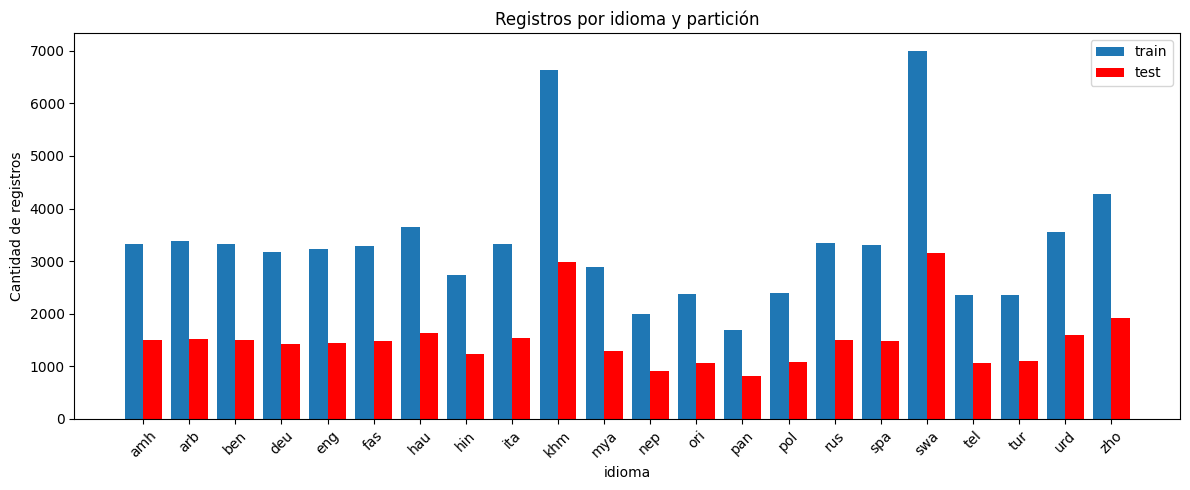

idioma,amh,arb,ben,deu,eng,fas,hau,hin,ita,khm,...,ori,pan,pol,rus,spa,swa,tel,tur,urd,zho
train,3332.0,3380.0,3333.0,3180.0,3222.0,3295.0,3651.0,2744.0,3334.0,6640.0,...,2368.0,1700.0,2391.0,3348.0,3305.0,6991.0,2366.0,2364.0,3563.0,4280.0
test,1501.0,1521.0,1501.0,1432.0,1452.0,1484.0,1644.0,1236.0,1538.0,2988.0,...,1066.0,809.0,1077.0,1508.0,1488.0,3147.0,1066.0,1093.0,1606.0,1927.0
% test,31.1,31.0,31.1,31.0,31.1,31.1,31.0,31.1,31.6,31.0,...,31.0,32.2,31.1,31.1,31.0,31.0,31.1,31.6,31.1,31.0


In [8]:
# Cantidad de registros por idioma y partición
conteo = pd.DataFrame({'train': train['idioma'].value_counts(),
                       'test': test['idioma'].value_counts()}).sort_index()
x = np.arange(len(conteo))

plt.figure(figsize = (12, 5))
plt.bar(x - 0.2, conteo['train'], width = 0.4, label = 'train')
plt.bar(x + 0.2, conteo['test'], width = 0.4, color = 'red', label = 'test')
plt.xticks(x, conteo.index, rotation = 45)
plt.xlabel('idioma')
plt.ylabel('Cantidad de registros')
plt.title('Registros por idioma y partición')
plt.legend()
plt.tight_layout()
plt.show()

conteo['% test'] = round(100 * conteo['test'] / (conteo['train'] + conteo['test']), 1)
display(conteo.T)

Utilizar únicamente español e inglés, dado que son los únicos idiomas que conocemos, sacrificaría generalización del modelo, además que usaría solo una porción mínima de todo el corpus disponible. Es por esto que resulta más adecuado tratar con todos los idiomas disponibles. 

Teniendo esto en consideración, la implementación de Tokenización podría resultar compleja, así que evaluaremos alternativas para el preprocesamiento de la información.

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Subtarea 1: Polarización</span></div>

	 Proporción de textos polarizados (train):
polarization
1    0.531
0    0.469
Name: proportion, dtype: float64


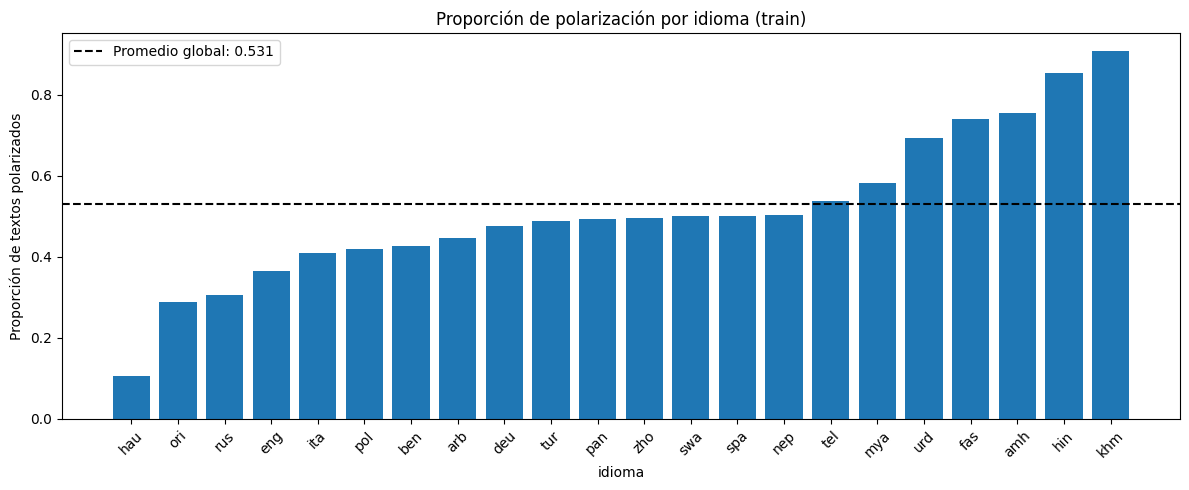

In [9]:
# Balance global de la variable binaria
print('\t Proporción de textos polarizados (train):')
print(train['polarization'].value_counts(normalize = True).round(3))

pol_idioma = train.groupby('idioma')['polarization'].mean().sort_values()

plt.figure(figsize = (12, 5))
plt.bar(pol_idioma.index, pol_idioma.values)
plt.axhline(train['polarization'].mean(), color = 'black', linestyle = '--',
            label = f'Promedio global: {round(train["polarization"].mean(), 3)}')
plt.xticks(rotation = 45)
plt.xlabel('idioma')
plt.ylabel('Proporción de textos polarizados')
plt.title('Proporción de polarización por idioma (train)')
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
# Ejemplos de textos polarizados y no polarizados
pd.set_option('display.max_colwidth', 200)
for idioma in ['eng', 'spa']:
    muestra = train[train['idioma'] == idioma].groupby('polarization').sample(3, random_state = random_state)
    print(f'\n\t Idioma: {idioma}')
    display(muestra[['text', 'polarization'] + tipos])


	 Idioma: eng


,text,polarization,political,racial/ethnic,religious,gender/sexual,other
15550,Valley demonstrators hold ceasefire rally to express,0,0,0,0,0,0
14335,Hamas calls for mobilization to repel PA security forces amid West Bank ops.,0,0,0,0,0,0
13377,TWO INDEPENDENT STATES End Israeli Atrocities End Israeli Apartheid FREE PALESTINE NOW IsraeliWarCrimes,0,0,0,0,0,0
13954,zionist terrorist psychopaths gave military allclear to kill civilians NYT The ZOF reportedly deemed upwards of 20 civilian casualties per airstrike an acceptable death toll.,1,1,1,0,0,0
14666,"BREAKING NEWS ! US FINANCIAL SECTOR UNDERGOING DESHYLOCKATION, IN RESPONSE TO RUSSIAN DENAZIFICATION.",1,1,1,0,0,0
14570,Open borders was always the policy and a tool of RW libertarians and capitalist oligarchs. Thats their irony.,1,1,0,0,0,0



	 Idioma: spa


,text,polarization,political,racial/ethnic,religious,gender/sexual,other
52235,india is parallel universe.,0,0,0,0,0,0
53971,jadejas injury = advantage india,0,0,0,0,0,0
52318,mis favos! la caja negra!!,0,0,0,0,0,0
53623,algunos vamos a perder la compasion que sentimos por el pueblo judio.,1,0,1,1,0,0
53155,lo de los piquitos es de maricon total,1,0,0,0,1,0
52217,barras de pan tenes gordo indigena,1,0,1,0,0,0


## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Subtarea 2: Tipo de polarización</span></div>

Como un texto no polarizado nunca tiene tipo, las proporciones de esta sección se calculan solo sobre los textos polarizados.

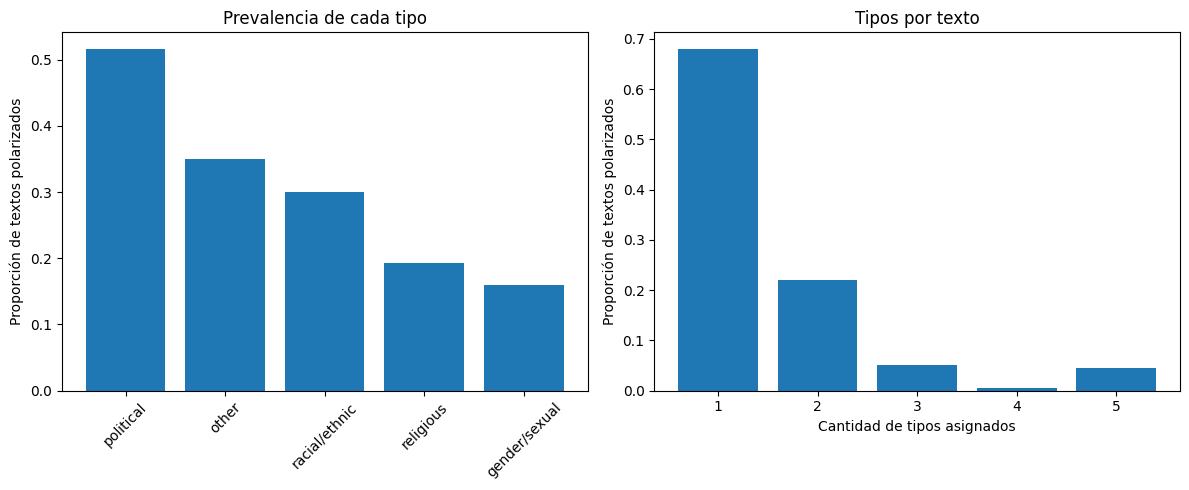

In [11]:
# Prevalencia de cada tipo y cantidad de tipos por texto
prev_tipos = si_pol[tipos].mean().sort_values(ascending = False)
n_tipos = si_pol[tipos].sum(axis = 1).value_counts(normalize = True).sort_index()

plt.figure(figsize = (12, 5))

plt.subplot(1, 2, 1)
plt.bar(prev_tipos.index, prev_tipos.values)
plt.xticks(rotation = 45)
plt.ylabel('Proporción de textos polarizados')
plt.title('Prevalencia de cada tipo')

plt.subplot(1, 2, 2)
plt.bar(n_tipos.index, n_tipos.values)
plt.xlabel('Cantidad de tipos asignados')
plt.ylabel('Proporción de textos polarizados')
plt.title('Tipos por texto')

plt.tight_layout()
plt.show()

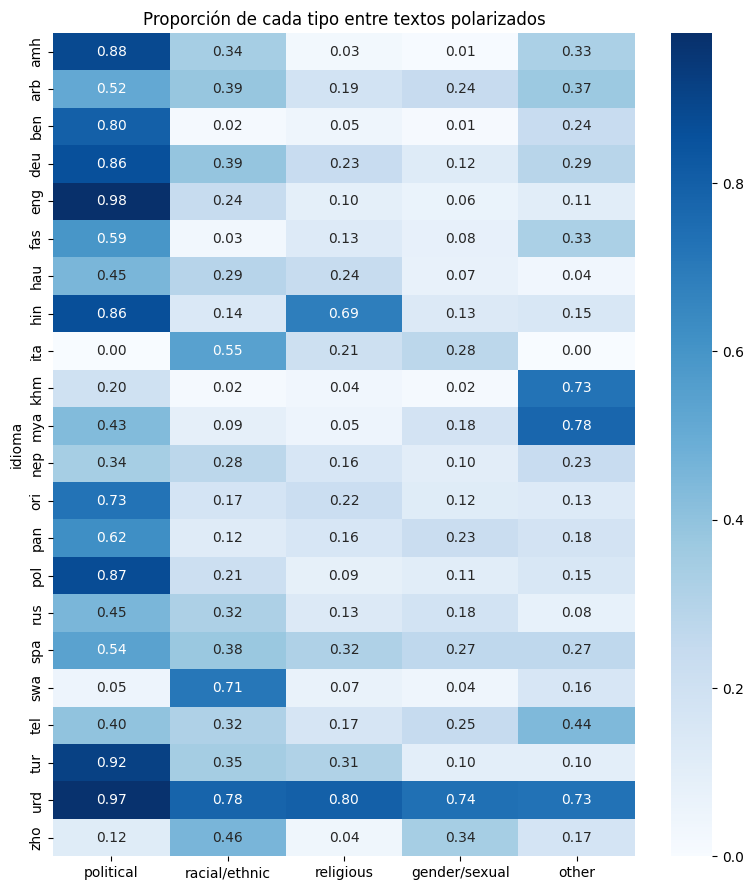

In [12]:
# Prevalencia de cada tipo por idioma
plt.figure(figsize = (8, 9))
sns.heatmap(si_pol.groupby('idioma')[tipos].mean(), annot = True, fmt = '.2f', cmap = 'Blues')
plt.title('Proporción de cada tipo entre textos polarizados')
plt.tight_layout()
plt.show()

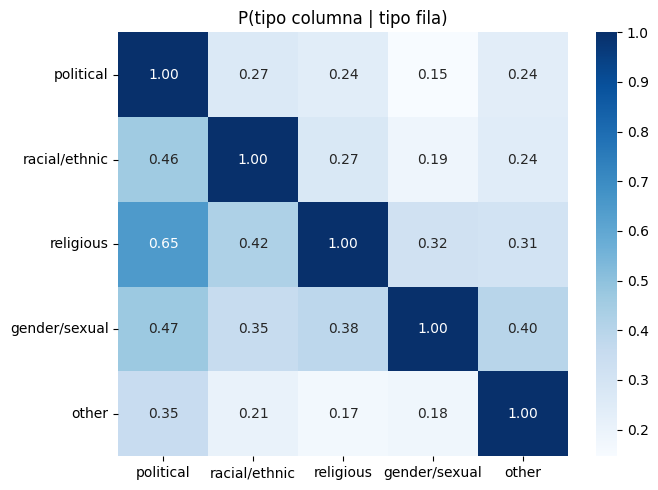

In [13]:
# Coocurrencia condicional: P(columna | fila)
co_tipos = si_pol[tipos].T @ si_pol[tipos]
co_tipos = co_tipos.div(np.diag(co_tipos), axis = 0)

plt.figure(figsize = (7, 5))
sns.heatmap(co_tipos, annot = True, fmt = '.2f', cmap = 'Blues')
plt.title('P(tipo columna | tipo fila)')
plt.tight_layout()
plt.show()

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Subtarea 3: Manifestación de la polarización</span></div>

Igual que en la subtarea anterior, se consideran solo los textos polarizados y, además, se excluyen los idiomas sin etiquetas de manifestación.

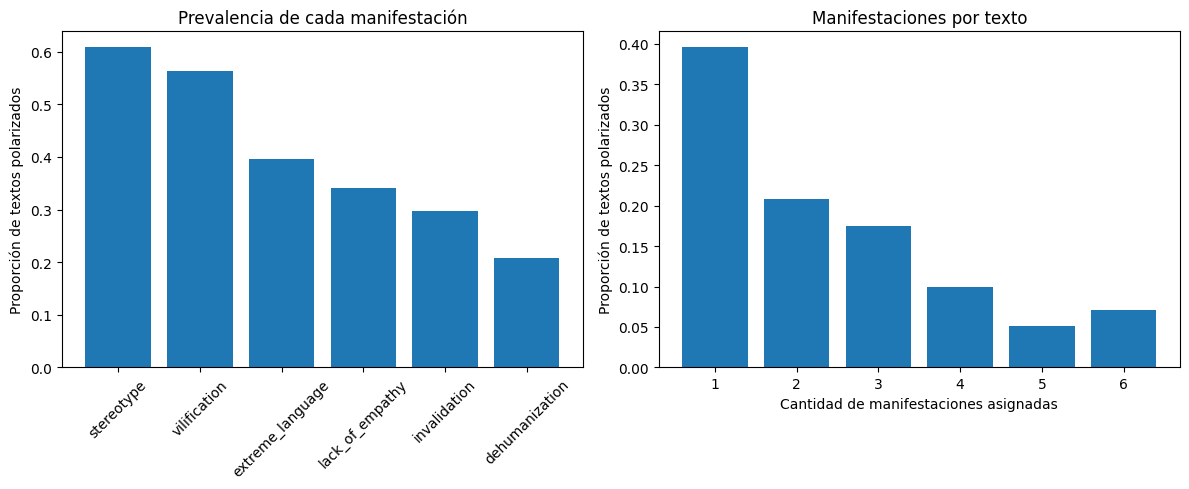

In [14]:
# Prevalencia de cada manifestación y cantidad de manifestaciones por texto
prev_manif = si_pol_manif[manifestaciones].mean().sort_values(ascending = False)
n_manif = si_pol_manif[manifestaciones].sum(axis = 1).value_counts(normalize = True).sort_index()

plt.figure(figsize = (12, 5))

plt.subplot(1, 2, 1)
plt.bar(prev_manif.index, prev_manif.values)
plt.xticks(rotation = 45)
plt.ylabel('Proporción de textos polarizados')
plt.title('Prevalencia de cada manifestación')

plt.subplot(1, 2, 2)
plt.bar(n_manif.index, n_manif.values)
plt.xlabel('Cantidad de manifestaciones asignadas')
plt.ylabel('Proporción de textos polarizados')
plt.title('Manifestaciones por texto')

plt.tight_layout()
plt.show()

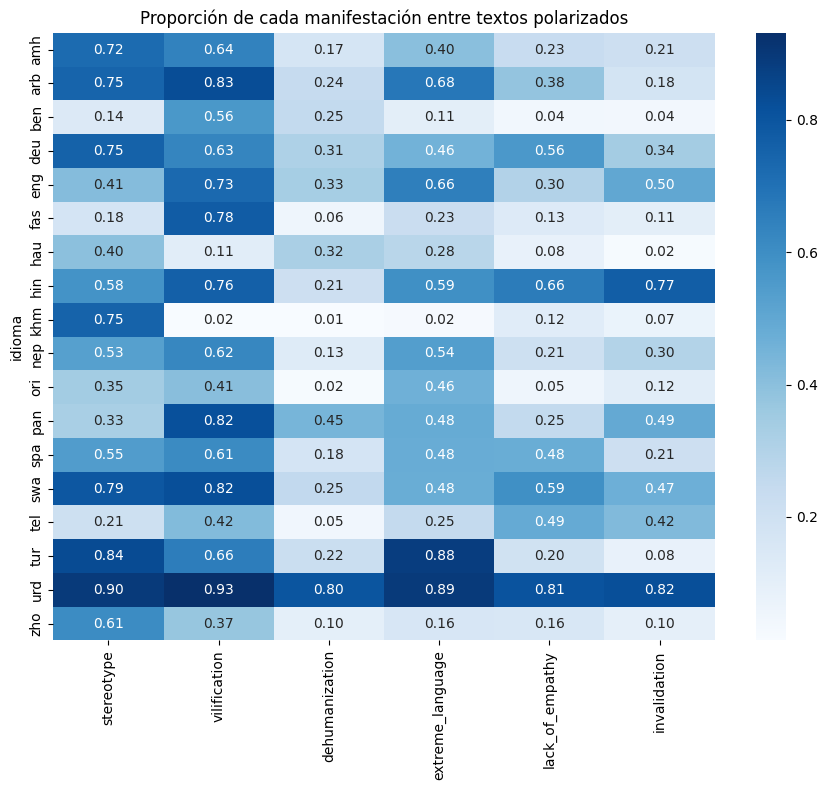

In [15]:
# Prevalencia de cada manifestación por idioma
plt.figure(figsize = (9, 8))
sns.heatmap(si_pol_manif.groupby('idioma')[manifestaciones].mean(), annot = True, fmt = '.2f', cmap = 'Blues')
plt.title('Proporción de cada manifestación entre textos polarizados')
plt.tight_layout()
plt.show()

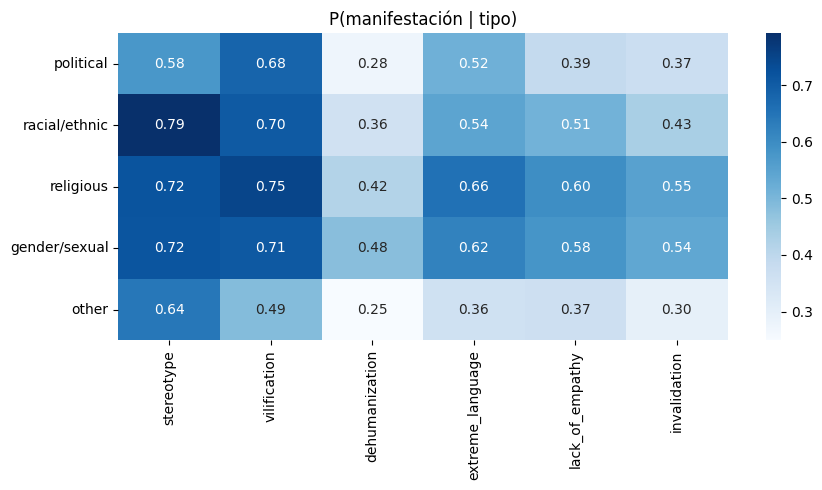

In [16]:
# Relación entre tipo y manifestación: P(manifestación | tipo)
tipo_manif = pd.DataFrame({t: si_pol_manif.loc[si_pol_manif[t] == 1, manifestaciones].mean() for t in tipos}).T

plt.figure(figsize = (9, 5))
sns.heatmap(tipo_manif, annot = True, fmt = '.2f', cmap = 'Blues')
plt.title('P(manifestación | tipo)')
plt.tight_layout()
plt.show()

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Longitud de los textos</span></div>

La longitud se mide en caracteres porque el chino, el jemer y el birmano no separan sus palabras con espacios, así que contar palabras con `split()` subestimaría mucho su longitud. Se omiten los valores atípicos en los diagramas de caja para que la escala sea legible.

count    73681.0
mean       106.8
std         75.1
min          2.0
25%         54.0
50%         89.0
75%        131.0
max       2680.0
Name: n_caracteres, dtype: float64

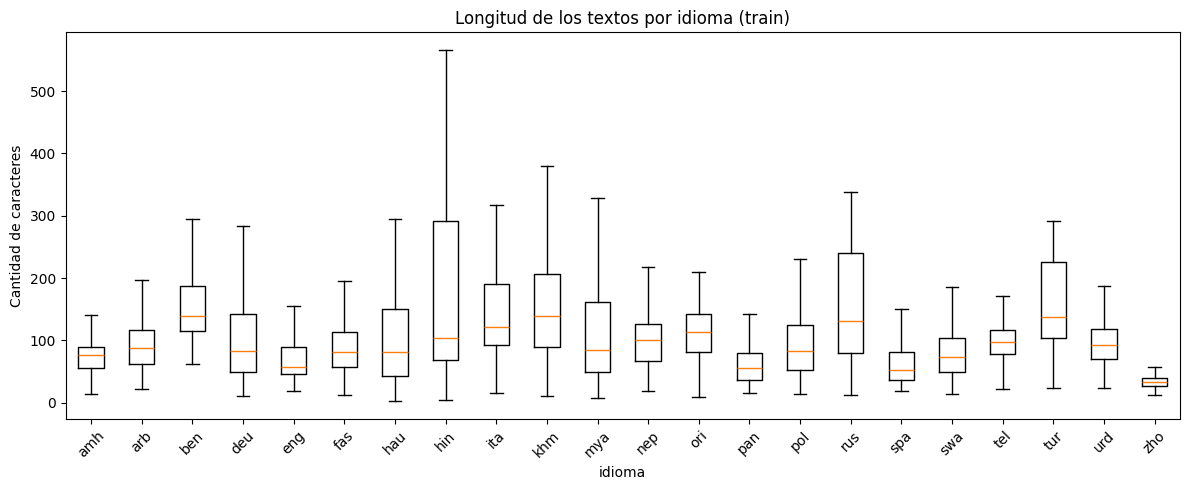

In [17]:
train['n_caracteres'] = train['text'].str.len()
display(train['n_caracteres'].describe().round(1))

idiomas = sorted(train['idioma'].unique())

plt.figure(figsize = (12, 5))
plt.boxplot([train.loc[train['idioma'] == i, 'n_caracteres'] for i in idiomas],
            tick_labels = idiomas, showfliers = False)
plt.xticks(rotation = 45)
plt.xlabel('idioma')
plt.ylabel('Cantidad de caracteres')
plt.title('Longitud de los textos por idioma (train)')
plt.tight_layout()
plt.show()

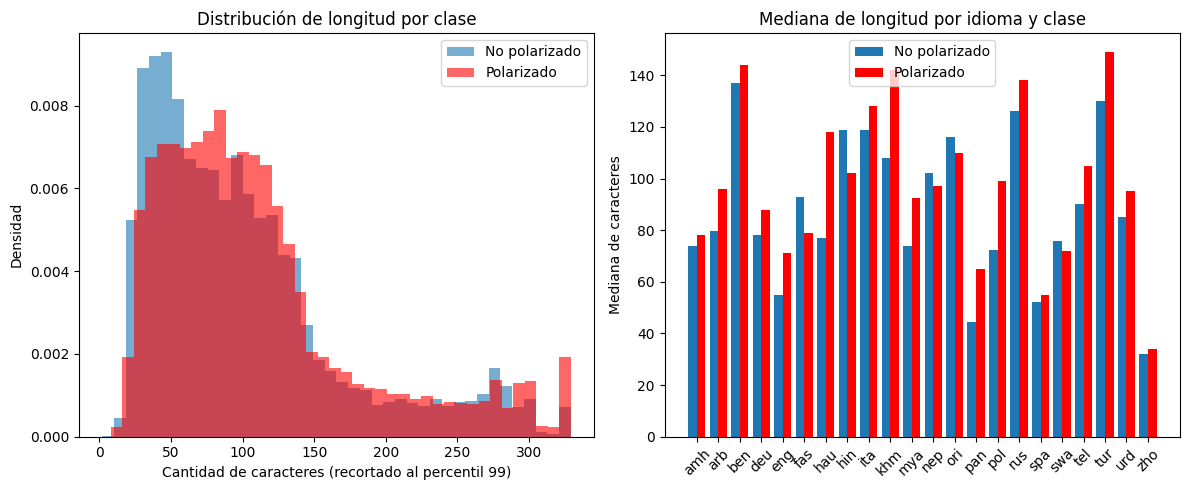

In [18]:
# Longitud según polarización
limite = train['n_caracteres'].quantile(0.99)
mediana = train.groupby(['idioma', 'polarization'])['n_caracteres'].median().unstack()
x = np.arange(len(mediana))

plt.figure(figsize = (12, 5))

plt.subplot(1, 2, 1)
plt.hist(no_pol['text'].str.len().clip(upper = limite), bins = 40, alpha = 0.6, density = True, label = 'No polarizado')
plt.hist(si_pol['text'].str.len().clip(upper = limite), bins = 40, alpha = 0.6, density = True, color = 'red', label = 'Polarizado')
plt.xlabel('Cantidad de caracteres (recortado al percentil 99)')
plt.ylabel('Densidad')
plt.title('Distribución de longitud por clase')
plt.legend()

plt.subplot(1, 2, 2)
plt.bar(x - 0.2, mediana[0], width = 0.4, label = 'No polarizado')
plt.bar(x + 0.2, mediana[1], width = 0.4, color = 'red', label = 'Polarizado')
plt.xticks(x, mediana.index, rotation = 45)
plt.ylabel('Mediana de caracteres')
plt.title('Mediana de longitud por idioma y clase')
plt.legend()

plt.tight_layout()
plt.show()

## <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Comparación entre entrenamiento y prueba</span></div>

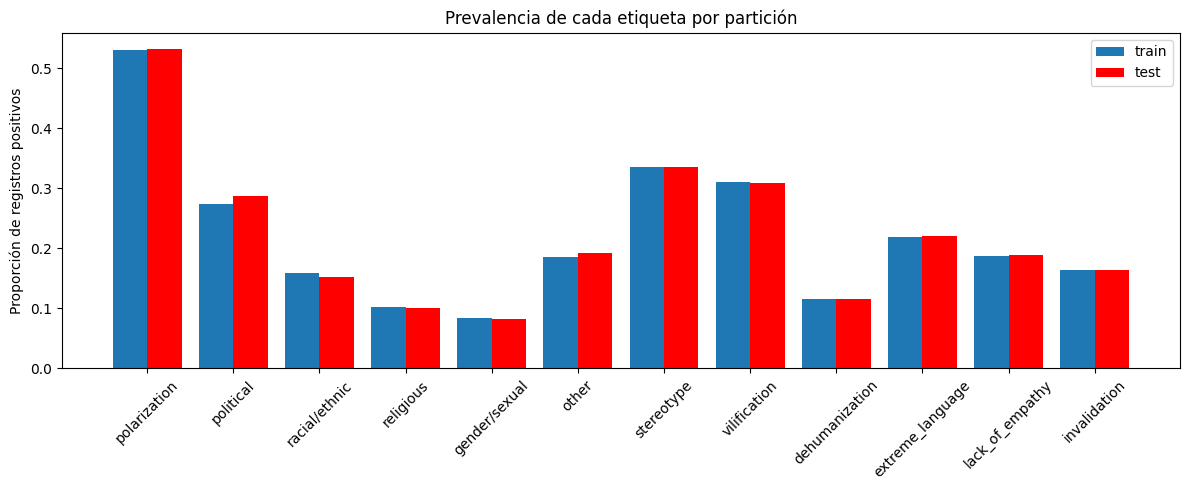

Diferencia absoluta máxima: 0.0137 (political)


In [19]:
# Prevalencia de cada etiqueta en ambas particiones
comparacion = pd.DataFrame({'train': train[etiquetas].mean(), 'test': test[etiquetas].mean()})
x = np.arange(len(comparacion))

plt.figure(figsize = (12, 5))
plt.bar(x - 0.2, comparacion['train'], width = 0.4, label = 'train')
plt.bar(x + 0.2, comparacion['test'], width = 0.4, color = 'red', label = 'test')
plt.xticks(x, comparacion.index, rotation = 45)
plt.ylabel('Proporción de registros positivos')
plt.title('Prevalencia de cada etiqueta por partición')
plt.legend()
plt.tight_layout()
plt.show()

diferencia = (comparacion['train'] - comparacion['test']).abs()
print(f'Diferencia absoluta máxima: {round(diferencia.max(), 4)} ({diferencia.idxmax()})')

# <div style="border-left:4px solid #524e64;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Conclusiones</span></div>

In [20]:
# Tabla resumen por idioma
resumen = pd.DataFrame({
    'n_train': train.groupby('idioma').size(),
    'n_test': test.groupby('idioma').size(),
    '% polarizado': (100 * train.groupby('idioma')['polarization'].mean()).round(1),
    'subtarea 3': train.groupby('idioma')['stereotype'].apply(lambda s: s.notnull().any()),
    'mediana caracteres': train.groupby('idioma')['n_caracteres'].median()
})
display(resumen)

,n_train,n_test,% polarizado,subtarea 3,mediana caracteres
idioma,,,,,
amh,3332,1501,75.6,True,77.0
arb,3380,1521,44.7,True,88.5
ben,3333,1501,42.7,True,139.0
deu,3180,1432,47.5,True,83.0
eng,3222,1452,36.5,True,58.0
fas,3295,1484,74.1,True,81.0
hau,3651,1644,10.7,True,82.0
hin,2744,1236,85.5,True,103.0
ita,3334,1538,41.0,False,121.0


* **Tamaño y particiones.** Hay 73,681 textos de entrenamiento y 33,288 de prueba en 22 idiomas. Todos los idiomas reservan cerca del 31% de sus textos para prueba, y casi todos tienen entre 2 mil y 3.7 mil textos de entrenamiento; las excepciones son el jemer (`khm`) y el suajili (`swa`), con unos 7 mil, el chino (`zho`), con 4.3 mil, y el panyabí (`pan`), con 1,700.
* **Calidad.** No hay valores nulos en los textos ni en las subtareas 1 y 2, y las etiquetas respetan la jerarquía: ningún texto no polarizado tiene tipo o manifestación, y todo texto polarizado tiene al menos uno de cada uno. La subtarea 3 no está anotada en italiano, birmano, polaco ni ruso (11,962 textos), así que esos idiomas deben excluirse al entrenar y evaluar esa subtarea.
* **Duplicados y fuga.** Solo 3 textos se repiten en `train` y 4 textos de `test` aparecen idénticos en `train`. Esta comparación exacta es una cota inferior: en el preprocesamiento se repite sobre el texto limpio y aparecen bastantes más.
* **Subtarea 1.** A nivel global las clases están balanceadas (53.1% polarizado), pero por idioma la proporción va del 10.7% en hausa al 90.8% en jemer, con el hindi (85.5%), el amhárico (75.6%) y el persa (74.1%) también muy cargados hacia la clase positiva. Un modelo multilingüe puede aprender a usar el idioma como atajo, por lo que conviene reportar métricas por idioma además de la global.
* **Subtarea 2.** Entre los textos polarizados, el tipo más común es el político (52%), seguido de *other* (35%), el racial/étnico (30%), el religioso (19%) y el de género/sexual (16%). Dos de cada tres textos tienen un solo tipo. La distribución cambia mucho entre idiomas: el político domina en 16 de ellos, pero en suajili e italiano casi no aparece y predomina el racial/étnico, y en jemer y birmano predomina *other*. El urdu es un caso aparte: el 71% de sus textos polarizados tiene los cinco tipos a la vez, lo que apunta a un criterio de anotación distinto.
* **Subtarea 3.** Las manifestaciones más frecuentes son el estereotipo (61%) y la vilificación (56%), y la deshumanización es la más rara (21%). A diferencia de los tipos, aquí lo normal es que un texto tenga varias: solo el 40% tiene una sola manifestación.
* **Longitud.** Los textos son cortos (mediana de 89 caracteres), y los polarizados son apenas más largos que los no polarizados (94 contra 84), así que la longitud por sí sola no distingue las clases.
* **Entrenamiento contra prueba.** La prevalencia de cada etiqueta es casi igual en ambas particiones (la diferencia máxima es de 1.4 puntos, en *political*), así que un modelo validado con una parte de `train` debería comportarse de forma parecida en `test`.